## Decision Tree implementation

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.datasets import load_iris
data = load_iris()


In [5]:
data.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

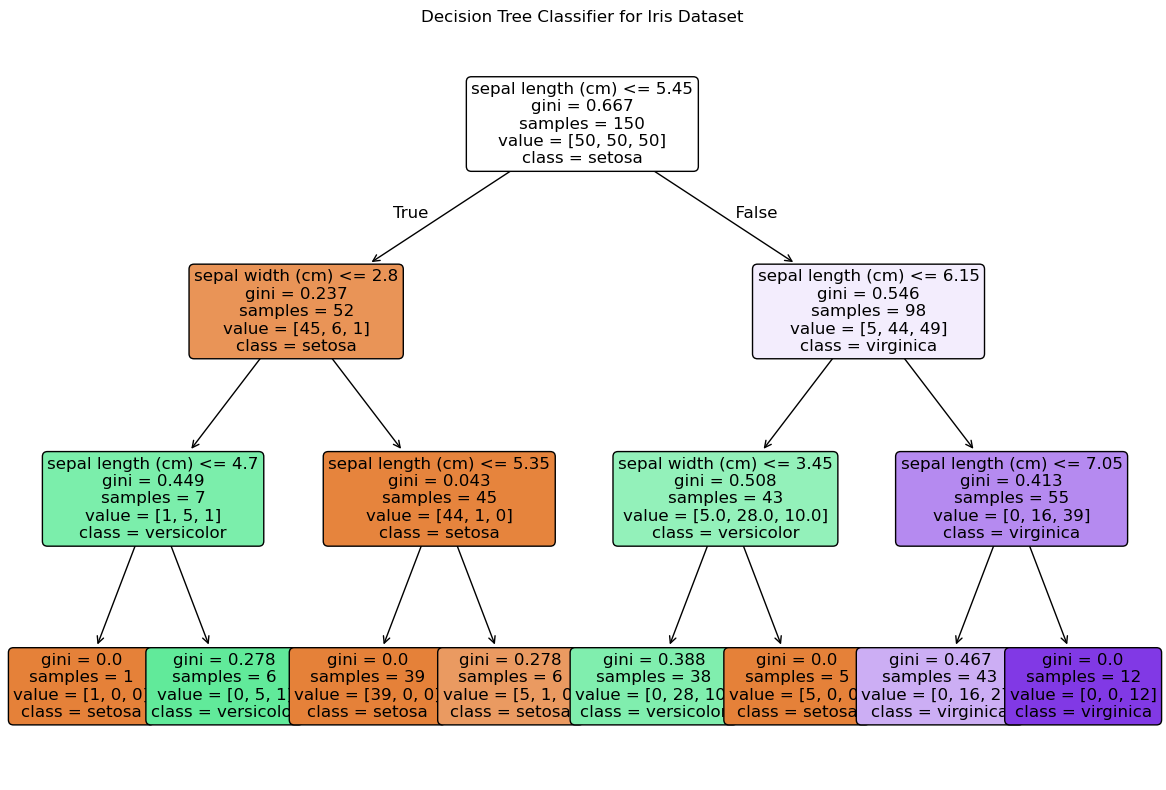

In [10]:
X = data.data[:, :2]
y = data.target

model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X, y)

plt.figure(figsize=(12, 8))
plot_tree(
    model, 
    feature_names=data.feature_names[:2],
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=12
)
plt.title("Decision Tree Classifier for Iris Dataset")
plt.tight_layout()
plt.show()

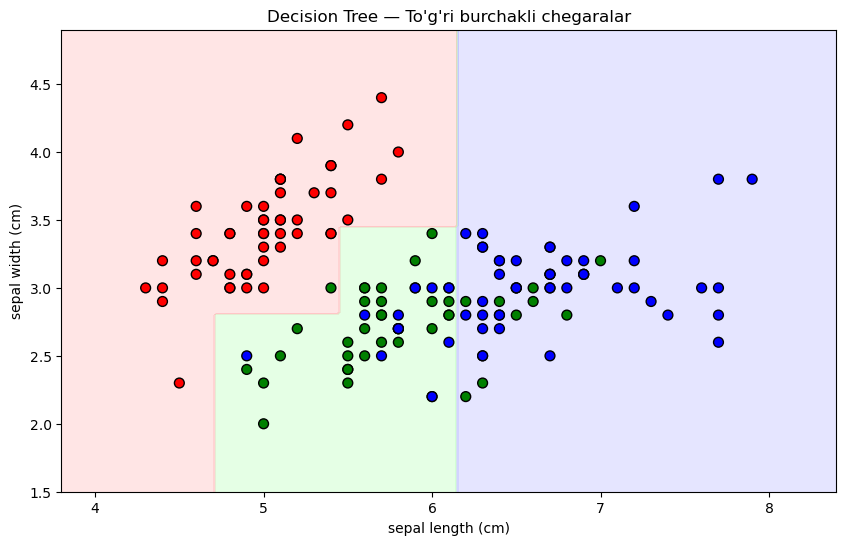

In [29]:

# Observing decision boundary 
from matplotlib.colors import ListedColormap

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                      np.arange(y_min, y_max, 0.02))

Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)                 

plt.figure(figsize=(10, 6))
cmap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])   
plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap)             
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=ListedColormap(['red', 'green', 'blue']),
            edgecolors='black', s=50)                      
plt.xlabel(data.feature_names[0])
plt.ylabel(data.feature_names[1])
plt.title("Decision Tree — To'g'ri burchakli chegaralar")
plt.show()

In [23]:
conditions = [
    ("Pure node", 50, 0),
    ("Virtually pure node", 45, 5),
    ("Little impurity", 40, 10),
    ("Impure node", 30, 20),
    ("Fully impure node", 25, 25)
]


print(f"Condition            | Spam  | Not Spam| Gini Impurity")
print("-" * 60)
for condition, spam, not_spam in conditions:
    total = spam + not_spam
    gini_impurity = 1 - (spam / total) ** 2 - (not_spam / total) ** 2
    print(f"{condition:<20} | {spam:>5} | {not_spam:>7} | {gini_impurity:>8.4f}")


Condition            | Spam  | Not Spam| Gini Impurity
------------------------------------------------------------
Pure node            |    50 |       0 |   0.0000
Virtually pure node  |    45 |       5 |   0.1800
Little impurity      |    40 |      10 |   0.3200
Impure node          |    30 |      20 |   0.4800
Fully impure node    |    25 |      25 |   0.5000


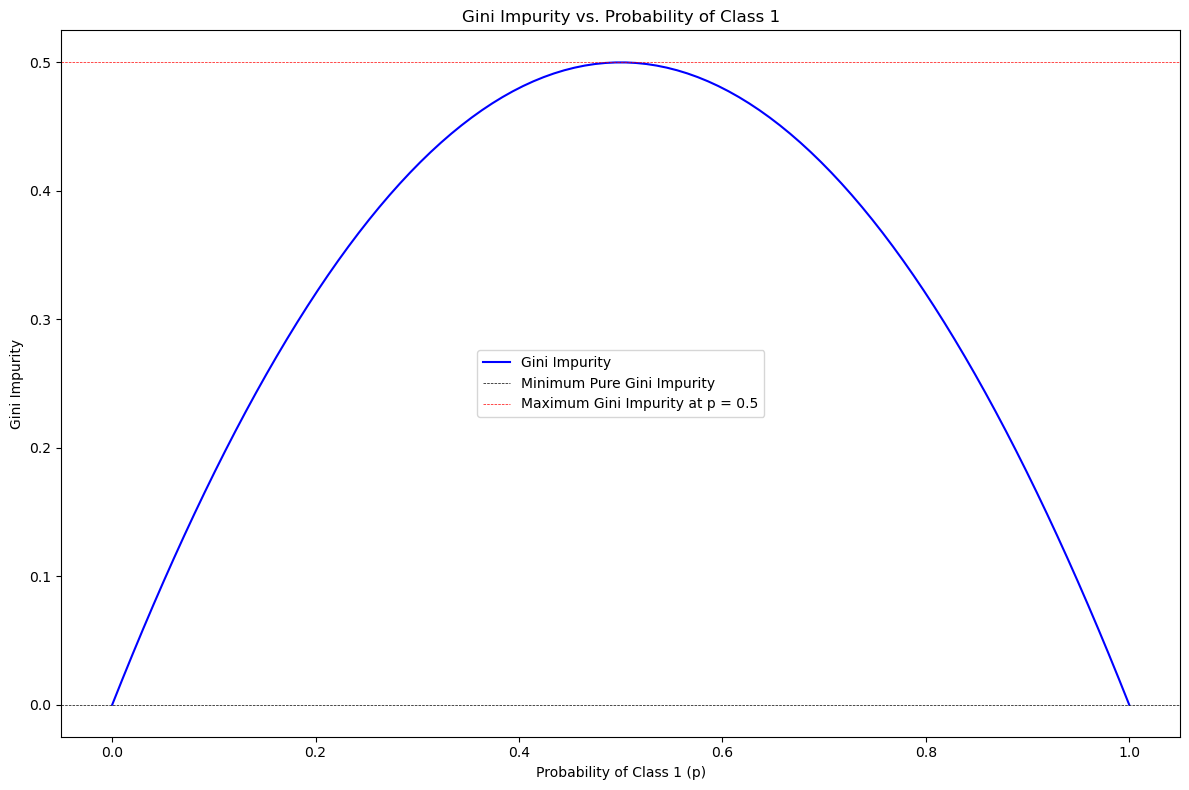

In [28]:
p_values = np.linspace(0, 1, 100)
gini_values = 1 - p_values**2 - (1-p_values)**2

plt.figure(figsize=(12, 8))

plt.plot(p_values, gini_values,  "b-", label='Gini Impurity')
plt.title("Gini Impurity vs. Probability of Class 1")
plt.xlabel("Probability of Class 1 (p)")
plt.ylabel("Gini Impurity")
plt.axhline(y=0, color='black', lw=0.5, ls='--', label="Minimum Pure Gini Impurity")
plt.axhline(y=0.5, color='red', lw=0.5, ls='--', label='Maximum Gini Impurity at p = 0.5')
plt.legend()    
plt.tight_layout()
plt.show()
